# Trabalho Prático 06 - Agentes Inteligentes
### GCC 128 - Inteligência Artificial
**Professor:** Ahmed Ali Abdalla Esmin

**Aluno:** Tobias Maugus Bueno Cougo

---
## Assistente de Estudos com Agentes Colaborativos

Esta aplicação usa **dois agentes inteligentes**, orquestrados com **LangGraph**,
que colaboram para transformar qualquer tema em um material de estudo:

1. **Agente Pesquisador** — usa uma **ferramenta** de busca na Wikipédia para
   reunir informações confiáveis sobre o tema pedido.
2. **Agente Tutor** — lê a pesquisa e produz um material de estudo estruturado
   (resumo, pontos-chave e perguntas de revisão).

O LLM usado é o **Groq** (gratuito), através do pacote `langchain-groq`.

## 1. Instalação das dependências

In [2]:
# Execute esta célula no Google Colab (ou no seu ambiente local)
%pip install -q langgraph langchain-groq langchain-core wikipedia


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Configuração da chave de API (Groq)

In [3]:
import os
from getpass import getpass

if "GROQ_API_KEY" not in os.environ or not os.environ["GROQ_API_KEY"]:
    os.environ["GROQ_API_KEY"] = getpass("Cole aqui sua chave gratuita da Groq: ")


## 3. Ferramenta (tool): busca na Wikipédia

Esta é a **ferramenta** exigida pela atividade. O Agente Pesquisador a usa
para buscar informações atualizadas e confiáveis sobre o tema pedido, em vez
de depender só do conhecimento interno do LLM.

In [4]:
import wikipedia
from langchain_core.tools import tool

wikipedia.set_lang("pt")

@tool
def buscar_wikipedia(consulta: str) -> str:
    """Busca um resumo sobre um termo ou tema na Wikipédia em português.
    Use esta ferramenta sempre que precisar de informações factuais sobre um assunto.
    """
    try:
        resumo = wikipedia.summary(consulta, sentences=8, auto_suggest=True)
        return resumo
    except wikipedia.exceptions.DisambiguationError as e:
        opcoes = ", ".join(e.options[:5])
        return f"O termo '{consulta}' é ambíguo. Opções mais específicas: {opcoes}."
    except wikipedia.exceptions.PageError:
        return f"Não foi encontrada nenhuma página na Wikipédia para '{consulta}'."
    except Exception as e:
        return f"Erro ao buscar na Wikipédia: {e}"


## 4. Modelo de linguagem (Groq)

Usamos o `openai/gpt-oss-120b`, um modelo de chat disponibilizado pela Groq, com `temperature=0` para respostas mais consistentes.

In [5]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)


## 5. Agente 1 — Pesquisador

Criado com `create_react_agent` do LangGraph: um agente que decide sozinho
quando chamar a ferramenta `buscar_wikipedia`, lê o resultado e formula uma
resposta com base nele (padrão **ReAct**: raciocinar + agir).

In [ ]:
from langgraph.prebuilt import create_react_agent

PROMPT_PESQUISADOR = """Você é um agente pesquisador. Seu único trabalho é usar a
ferramenta `buscar_wikipedia` para reunir informações confiáveis sobre o tema
pedido pelo usuário, e depois apresentar um texto corrido (não em tópicos) com
os principais fatos encontrados. Sempre utilize a ferramenta antes de
responder — nunca responda só com conhecimento próprio."""

agente_pesquisador = create_react_agent(
    model=llm,
    tools=[buscar_wikipedia],
    prompt=PROMPT_PESQUISADOR,
)



C:\Users\tobia\AppData\Local\Temp\ipykernel_26056\77179703.py:9: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agente_pesquisador = create_react_agent(


## 6. Agente 2 — Tutor

Recebe o texto do Agente Pesquisador e o transforma em material de estudo.
Este agente **não usa ferramentas** — seu trabalho é só organizar e didatizar
a informação já pesquisada.

In [7]:
from langchain_core.prompts import ChatPromptTemplate

PROMPT_TUTOR = ChatPromptTemplate.from_messages([
    ("system",
     "Você é um agente tutor. A partir do texto de pesquisa fornecido, produza "
     "um material de estudo em Markdown com, nesta ordem: "
     "(1) um resumo de até 5 linhas; "
     "(2) de 4 a 6 pontos-chave em tópicos; "
     "(3) 3 perguntas de revisão, cada uma seguida do gabarito. "
     "Seja claro, didático e não invente informações fora do texto fornecido."),
    ("human", "Tema: {tema}\n\nTexto de pesquisa:\n{pesquisa}"),
])

agente_tutor = PROMPT_TUTOR | llm


## 7. Orquestração dos agentes com LangGraph

O `StateGraph` define um **estado compartilhado** entre os agentes e o fluxo
de execução: `START → pesquisador → tutor → END`. A saída de um agente
(`pesquisa`) vira a entrada do próximo.

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class EstadoEstudo(TypedDict):
    tema: str
    pesquisa: str
    material_de_estudo: str


def no_pesquisador(estado: EstadoEstudo) -> dict:
    """Executa o Agente Pesquisador e guarda o resultado no estado."""
    resposta = agente_pesquisador.invoke({
        "messages": [("human", f"Pesquise sobre: {estado['tema']}")]
    })
    texto_pesquisa = resposta["messages"][-1].content
    return {"pesquisa": texto_pesquisa}


def no_tutor(estado: EstadoEstudo) -> dict:
    """Executa o Agente Tutor usando a pesquisa já feita."""
    resposta = agente_tutor.invoke({
        "tema": estado["tema"],
        "pesquisa": estado["pesquisa"],
    })
    return {"material_de_estudo": resposta.content}


grafo = StateGraph(EstadoEstudo)
grafo.add_node("pesquisador", no_pesquisador)
grafo.add_node("tutor", no_tutor)
grafo.add_edge(START, "pesquisador")
grafo.add_edge("pesquisador", "tutor")
grafo.add_edge("tutor", END)

app = grafo.compile()
print("Grafo de agentes compilado com sucesso.")


Grafo de agentes compilado com sucesso.


## 8. Visualização do grafo de agentes

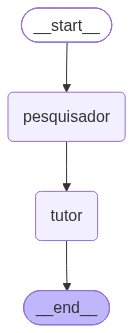

In [9]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))


## 9. Execução de exemplo

Basta trocar o valor de `tema` para estudar qualquer outro assunto.

In [10]:
resultado = app.invoke({
    "tema": "Redes Neurais Artificiais",
    "pesquisa": "",
    "material_de_estudo": "",
})

print("=" * 70)
print("PESQUISA DO AGENTE PESQUISADOR")
print("=" * 70)
print(resultado["pesquisa"])

print()
print("=" * 70)
print("MATERIAL DE ESTUDO DO AGENTE TUTOR")
print("=" * 70)
print(resultado["material_de_estudo"])


PESQUISA DO AGENTE PESQUISADOR
As redes neurais artificiais (RNAs) são modelos computacionais inspirados no sistema nervoso central dos animais, sobretudo no cérebro, e foram concebidas para reproduzir, de forma simplificada, o modo como neurônios biológicos processam informações. Cada rede é constituída por unidades elementares – os neurônios artificiais – que recebem sinais de entrada, os ponderam por meio de pesos sinápticos, aplicam‑les uma função de ativação e transmitem o resultado a outros neurônios. Esse fluxo de dados ocorre em camadas (entrada, ocultas e saída) e se repete até que um neurônio de saída seja ativado, permitindo que a rede classifique ou gere uma resposta a partir dos padrões aprendidos. Essa arquitetura permite que as RNAs realizem aprendizado de máquina e reconhecimento de padrões, sendo aplicáveis a tarefas complexas que são difíceis de resolver por programação baseada em regras, como visão computacional, reconhecimento de fala, tradução automática e diagnóst